# Projet MIDL — Partie 1 : Tronc Commun
## Classification de chiffres manuscrits (MNIST) par réseau de neurones

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Reproductibilité
SEED = 42
np.random.seed(SEED)

# Choix du modèle et représentation des données:
Problème choisis: classification des chiffres manuscrits.
- Chaque observation est une image en niveaux de gris de taille 28\28 pixels (valeurs entières de 0 à 255).
- **Vectorisation** : L'image 2D est représentée par un vecteur de R^d avec d = 28 * 28 = 784.
- **Normalisation** : Les intensités sont ramenées dans [0, 1] en divisant par 255.
- **Séparation des données** :
  - **Entraînement** : 50 000 exemples pour ajuster les paramètres.
  - **Validation** : 10 000 exemples (extraits du jeu d'entraînement initial) pour suivre la généralisation et détecter le sur-apprentissage.
  - **Test** : 10 000 exemples tenus totalement à l'écart jusqu'à l'évaluation finale.


In [3]:
px_size = 28  # taille des images
d = px_size * px_size  # dimension des images vectorisées

def read_images(path):
    # dtype=np.uint8 : 256 niveaux de gris (0-255)
    return np.fromfile(path, dtype=np.uint8, offset=16).reshape(-1, px_size, px_size) 
    """ Le reshape permet de séparer les images (28x28)
    Dimension 1 : nombre d'images, Dimension 2 et 3 : taille des images (28x28)"""

def read_labels(path):
    # 1 octet par étiquette, donc dtype=np.uint8
    return np.fromfile(path, dtype=np.uint8, offset=8)

# Données d'entrainement
path_images = "./mnist/train-images-idx3-ubyte/train-images-idx3-ubyte"
path_labels = "./mnist/train-labels-idx1-ubyte/train-labels-idx1-ubyte"
# et de test:
path_test_images = "./mnist/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte"
path_test_labels = "./mnist/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte"


def load_mnist_numpy():
  X_all = read_images(path_images).reshape(-1, d) / 255.0 # Ici le reshape permet de vectoriser les images (28x28 -> 784)
  y_all = read_labels(path_labels)
  X_test = read_images(path_test_images).reshape(-1, d) / 255.0
  y_test = read_labels(path_test_labels)
  return X_all, y_all, X_test, y_test

X_all, y_all, X_test, y_test = load_mnist_numpy()

perm = np.random.permutation(len(X_all))
X_all, y_all = X_all[perm], y_all[perm]

X_train, y_train = X_all[:50000], y_all[:50000]
X_val, y_val = X_all[50000:], y_all[50000:]

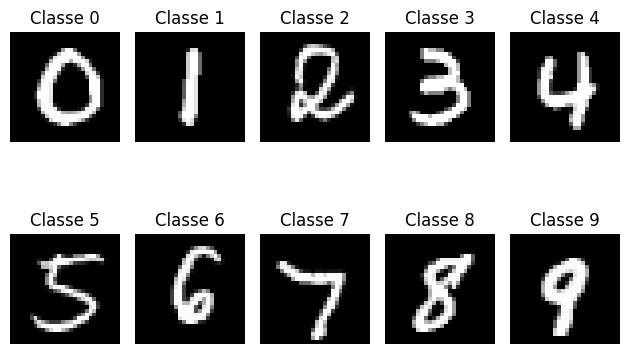

Effectifs par classe dans X_train : {0: 4952, 1: 5583, 2: 4942, 3: 5172, 4: 4888, 5: 4524, 6: 4899, 7: 5227, 8: 4846, 9: 4967}


In [4]:
# Visualisation d'un échantillon de chaque classe
fig, axes = plt.subplots(2, 5) # 2 lignes, 5 colonnes
for c in range(10):
    idx = np.where(y_train == c)[0][0] # premier indice de la classe c
    ax = axes[c // 5, c % 5] # position dans la grille
    ax.imshow(X_train[idx].reshape(28, 28), cmap="gray") # cmap "gray" permet d'afficher les niveaux de gris
    ax.set_title(f"Classe {c}")
    ax.axis("off")
plt.tight_layout()
plt.show()

counts = np.bincount(y_train)
print("Effectifs par classe dans X_train :", dict(enumerate(counts.tolist())))

## Fonctions et structures pour l'entrainement
## Cette partie est en chantier, ne pas hésiter à faire des modifs, j'ai commencé à coder les premières fonctions du cours

Perceptron:

In [ ]:
def partie_lineaire(variables, poids):
    assert len(variables) == len(poids), "Le nombre de variables doit être égal au nombre de poids"
    resultat = 0
    for i in range(len(variables)):
        resultat += variables[i] * poids[i]
    return resultat

def activation(x):
    return 1 if x >= 0 else 0

def perceptron(variables, poids):
    return activation(partie_lineaire(variables, poids))

def perceptron_affine(variables, poids, biais):
    return activation(partie_lineaire(variables, poids) + biais)

Neuronnes:

In [ ]:
class Neuronne:
    def __init__(self, nb_entrees):
        self.poids = np.random.randn(nb_entrees)  # initialisation aléatoire des poids
        self.biais = np.random.randn()  # initialisation aléatoire du biais

class Couche:
    def __init__(self, nb_neurones, nb_entrees):
        self.neurones = [Neuronne(nb_entrees) for _ in range(nb_neurones)]
